In [2]:
import numpy as np
import os

snapshots = [99, 50, 33, 25]

fields = [
    "SubhaloMassType",
    "SubhaloSFR",
    "SubhaloGasMetallicitySfrWeighted"
]

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap}")
    print("=" * 60)

    if not os.path.exists(filename):
        print("Fajl ne postoji!")
        continue

    data = np.load(filename)

    # Broj ID-jeva
    ids = data["SubhaloID"]

    print(f"\nBroj subhaloa (ID): {len(ids)}")

    # Provera svakog polja
    lengths = []

    for field in fields:

        array = data[field]

        lengths.append(len(array))

        print(f"{field}:")
        print(f"    Oblik: {array.shape}")
        print(f"    Broj redova: {len(array)}")

    # Provera jednakog broja redova
    if len(set(lengths + [len(ids)])) == 1:

        print("\nSVI NIZOVI IMAJU ISTI BROJ REDOVA.")

    else:

        print("\nGRESKA: BROJ REDOVA SE NE POKLAPA")

    # Provera ID-jeva
    expected_ids = np.arange(len(ids))

    if np.array_equal(ids, expected_ids):

        print("ID-jevi odgovaraju indeksima u katalogu.")

    else:

        print("GRESKA: ID-jevi nisu pravilno poređani")

    # Provera da li postoje duplikati
    if len(np.unique(ids)) == len(ids):

        print("Nema dupliranih ID-jeva.")

    else:

        print("GRESKA: Postoje duplirani ID-jevi.")

    # Provera nedostajućih vrednosti
    for field in fields:

        array = data[field]

        print(
            f"{field} | NaN vrednosti:",
            np.isnan(array).sum()
        )

print("\nKraj")


SNAPSHOT 99

Broj subhaloa (ID): 4371211
SubhaloMassType:
    Oblik: (4371211, 6)
    Broj redova: 4371211
SubhaloSFR:
    Oblik: (4371211,)
    Broj redova: 4371211
SubhaloGasMetallicitySfrWeighted:
    Oblik: (4371211,)
    Broj redova: 4371211

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 50

Broj subhaloa (ID): 5127294
SubhaloMassType:
    Oblik: (5127294, 6)
    Broj redova: 5127294
SubhaloSFR:
    Oblik: (5127294,)
    Broj redova: 5127294
SubhaloGasMetallicitySfrWeighted:
    Oblik: (5127294,)
    Broj redova: 5127294

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 33

Broj subhaloa (ID): 5621338
SubhaloMassType:
    Obl

In [3]:
import numpy as np

snapshots = [99, 50, 33, 25]

all_data = {}

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    loaded = np.load(filename)

    all_data[snap] = {
        key: loaded[key]
        for key in loaded.files
    }

    loaded.close()

    print(f'Snapshot {snap}: učitan')

Snapshot 99: učitan
Snapshot 50: učitan
Snapshot 33: učitan
Snapshot 25: učitan


In [4]:
snapshots = [99, 50, 33, 25]

filtered_data = {}

for snap in snapshots:

    print("\n" + "=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)

    data = all_data[snap]

    # Ukupan broj objekata pre filtriranja
    N_before = len(data["SubhaloID"])

    # Zvezdana masa (indeks 4)
    stellar_mass = data["SubhaloMassType"][:, 4]

    # Selekcija objekata sa pozitivnom zvezdanom masom
    mask = stellar_mass > 0

    # Broj objekata nakon filtriranja
    N_after = np.sum(mask)

    # Broj izbačenih objekata
    N_removed = N_before - N_after

    # Filtriranje svih polja istom maskom
    filtered_data[snap] = {
        field: data[field][mask]
        for field in [
            "SubhaloID",
            "SubhaloMassType",
            "SubhaloSFR",
            "SubhaloGasMetallicitySfrWeighted"
        ]
    }

    print("Broj objekata pre filtriranja:", N_before)
    print("Broj objekata nakon filtriranja:", N_after)
    print("Broj izbačenih objekata:", N_removed)

    print(
        "Procenat izbačenih objekata:",
        round(100 * N_removed / N_before, 2), "%"
    )

print("\nKraj")


SNAPSHOT 99
Broj objekata pre filtriranja: 4371211
Broj objekata nakon filtriranja: 337261
Broj izbačenih objekata: 4033950
Procenat izbačenih objekata: 92.28 %

SNAPSHOT 50
Broj objekata pre filtriranja: 5127294
Broj objekata nakon filtriranja: 492655
Broj izbačenih objekata: 4634639
Procenat izbačenih objekata: 90.39 %

SNAPSHOT 33
Broj objekata pre filtriranja: 5621338
Broj objekata nakon filtriranja: 680244
Broj izbačenih objekata: 4941094
Procenat izbačenih objekata: 87.9 %

SNAPSHOT 25
Broj objekata pre filtriranja: 5828784
Broj objekata nakon filtriranja: 836537
Broj izbačenih objekata: 4992247
Procenat izbačenih objekata: 85.65 %

Kraj


In [5]:
import numpy as np

final_data = {}

for snap in snapshots:

    data = filtered_data[snap]

    # Racunanje logSFR
    logSFR = np.full(len(data["SubhaloSFR"]), -np.inf)

    positive_sfr = data["SubhaloSFR"] > 0
    logSFR[positive_sfr] = np.log10(data["SubhaloSFR"][positive_sfr])

    # Uslov: logSFR > -4
    mask = logSFR > -4

    # Primena maske na sva polja
    final_data[snap] = {
        key: data[key][mask]
        for key in data.keys()
    }

    N_before = len(data["SubhaloID"])
    N_after = np.sum(mask)
    N_removed = N_before - N_after

    print("=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)
    print(f"Broj objekata pre dodatnog filtriranja: {N_before}")
    print(f"Broj objekata nakon dodatnog filtriranja: {N_after}")
    print(f"Broj izbacenih objekata: {N_removed}")
    print(f"Procenat izbacenih objekata: {100*N_removed/N_before:.2f} %")

SNAPSHOT 99
Broj objekata pre dodatnog filtriranja: 337261
Broj objekata nakon dodatnog filtriranja: 71575
Broj izbacenih objekata: 265686
Procenat izbacenih objekata: 78.78 %
SNAPSHOT 50
Broj objekata pre dodatnog filtriranja: 492655
Broj objekata nakon dodatnog filtriranja: 147241
Broj izbacenih objekata: 345414
Procenat izbacenih objekata: 70.11 %
SNAPSHOT 33
Broj objekata pre dodatnog filtriranja: 680244
Broj objekata nakon dodatnog filtriranja: 274398
Broj izbacenih objekata: 405846
Procenat izbacenih objekata: 59.66 %
SNAPSHOT 25
Broj objekata pre dodatnog filtriranja: 836537
Broj objekata nakon dodatnog filtriranja: 425208
Broj izbacenih objekata: 411329
Procenat izbacenih objekata: 49.17 %


# SFMS

In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor


protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]


# Veza između snapshot-a i crvenog pomaka
snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

# Rezultati
TNG_populations = {}
MW_statistics = {}

for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    # Izvlacenje zvezdane mase i SFR-a
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)

    # SFMS fit pomocu Huber regresije
    X = logM.reshape(-1, 1)
    y = logSFR

    huber = HuberRegressor()
    huber.fit(X, y)

    # Odstupanje od SFMS relacije
    logSFR_fit = huber.predict(X)
    delta_logSFR = logSFR - logSFR_fit

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": data["SubhaloID"][upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": data["SubhaloID"][lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })

    # Izdvajanje MW-like populacije iz upper populacije
    MW_mass = protoMWmass[z]

    MW_mask = np.abs(upper["logM"] - MW_mass) <= 0.2
    MW_like = upper[MW_mask].copy()

    # Cuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": data["SubhaloID"],
            "logM": logM,
            "logSFR": logSFR,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "mw_mass_like": MW_like,
        "huber": huber
    }

    # Osnovna statistika MW-like populacije
    MW_statistics[z] = {
        "N": len(MW_like),
        "median_logM": MW_like["logM"].median(),
        "median_logSFR": MW_like["logSFR"].median()
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija: {len(data['SubhaloID'])}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"MW-like populacija: {len(MW_like)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")

SNAPSHOT 99 | z = 0
Ukupan broj galaksija: 71575
Upper populacija: 68438
Lower populacija: 3137
MW-like populacija: 836
SFMS nagib: 0.8840
SFMS odsečak: -8.9508
SNAPSHOT 50 | z = 1
Ukupan broj galaksija: 147241
Upper populacija: 143950
Lower populacija: 3291
MW-like populacija: 1631
SFMS nagib: 0.9980
SFMS odsečak: -9.5499
SNAPSHOT 33 | z = 2
Ukupan broj galaksija: 274398
Upper populacija: 269569
Lower populacija: 4829
MW-like populacija: 1459
SFMS nagib: 1.0448
SFMS odsečak: -9.5911
SNAPSHOT 25 | z = 3
Ukupan broj galaksija: 425208
Upper populacija: 418428
Lower populacija: 6780
MW-like populacija: 1112
SFMS nagib: 1.0742
SFMS odsečak: -9.5490


In [12]:
for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    # Metalicitet iz izvornog TNG kataloga
    Z_weighted = data["SubhaloGasMetallicitySfrWeighted"]

    # Povezivanje metaliciteta sa ID-jevima objekata
    Z_dict = dict(zip(data["SubhaloID"], Z_weighted))

    # Dodavanje metaliciteta u postojece populacije
    for population in ["all", "upper", "lower"]:

        df = TNG_populations[z][population]

        df["Z_weighted"] = df["id"].map(Z_dict)

In [13]:
print(TNG_populations[0]["upper"].columns.tolist())
print(TNG_populations[0]["upper"].head())

['id', 'logM', 'logSFR', 'delta_logSFR', 'Z_weighted']
   id       logM    logSFR  delta_logSFR  Z_weighted
0   2  11.797364  1.240355     -0.237186    0.011027
1   3  11.234394  0.705811     -0.274090    0.018392
2   4  11.124962  0.150661     -0.732506    0.011017
3   6  11.461457  0.339321     -0.841294    0.023709
4  10  11.374335  0.164455     -0.939148    0.015832


# 2. SFMS

In [14]:
TNG_upper_fit = {}
MWupper = {}

for snap, z in snapshot_redshifts.items():

    upper = TNG_populations[z]["upper"]

    X = upper["logM"].values.reshape(-1, 1)
    y = upper["logSFR"].values

    huber_upper = HuberRegressor()
    huber_upper.fit(X, y)

    logSFR_fit = huber_upper.predict(X)

    delta_logSFR = y - logSFR_fit

    upper_mask_new = delta_logSFR > -1
    lower_mask_new = delta_logSFR <= -1

    upper_new = pd.DataFrame({
        "id": upper["id"].values[upper_mask_new],
        "logM": upper["logM"].values[upper_mask_new],
        "logSFR": upper["logSFR"].values[upper_mask_new],
        "Z_weighted": upper["Z_weighted"].values[upper_mask_new],
        "delta_logSFR": delta_logSFR[upper_mask_new]
    })

    MW_mass = protoMWmass[z]
    MW_mask = np.abs(upper_new["logM"] - MW_mass) <= 0.2
    MW_like = upper_new[MW_mask].copy()

    lower_new = pd.DataFrame({
        "id": upper["id"].values[lower_mask_new],
        "logM": upper["logM"].values[lower_mask_new],
        "logSFR": upper["logSFR"].values[lower_mask_new],
        "Z_weighted": upper["Z_weighted"].values[lower_mask_new],
        "delta_logSFR": delta_logSFR[lower_mask_new]
    })

    # Cuvanje kataloga MW objekata
    MWupper[z] = MW_like.copy()

    TNG_upper_fit[z] = {
        "all": upper.copy(),
        "upper": upper_new,
        "lower": lower_new,
        "mw_mass_like": MW_like,
        "huber": huber_upper
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Broj galaksija u novom SFMS fit-u: {len(upper)}")
    print(f"Nova upper populacija: {len(upper_new)}")
    print(f"Nova lower populacija: {len(lower_new)}")
    print(f"Nova MW like populacija: {len(MW_like)}")
    print(f"SFMS nagib: {huber_upper.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber_upper.intercept_:.4f}")


# Katalozi
MWupper0 = MWupper[0]
MWupper1 = MWupper[1]
MWupper2 = MWupper[2]
MWupper3 = MWupper[3]

SNAPSHOT 99 | z = 0
Broj galaksija u novom SFMS fit-u: 68438
Nova upper populacija: 68186
Nova lower populacija: 252
Nova MW like populacija: 804
SFMS nagib: 0.9060
SFMS odsečak: -9.1038
SNAPSHOT 50 | z = 1
Broj galaksija u novom SFMS fit-u: 143950
Nova upper populacija: 143797
Nova lower populacija: 153
Nova MW like populacija: 1624
SFMS nagib: 1.0052
SFMS odsečak: -9.5923
SNAPSHOT 33 | z = 2
Broj galaksija u novom SFMS fit-u: 269569
Nova upper populacija: 269328
Nova lower populacija: 241
Nova MW like populacija: 1457
SFMS nagib: 1.0477
SFMS odsečak: -9.6016
SNAPSHOT 25 | z = 3
Broj galaksija u novom SFMS fit-u: 418428
Nova upper populacija: 418115
Nova lower populacija: 313
Nova MW like populacija: 1112
SFMS nagib: 1.0751
SFMS odsečak: -9.5456


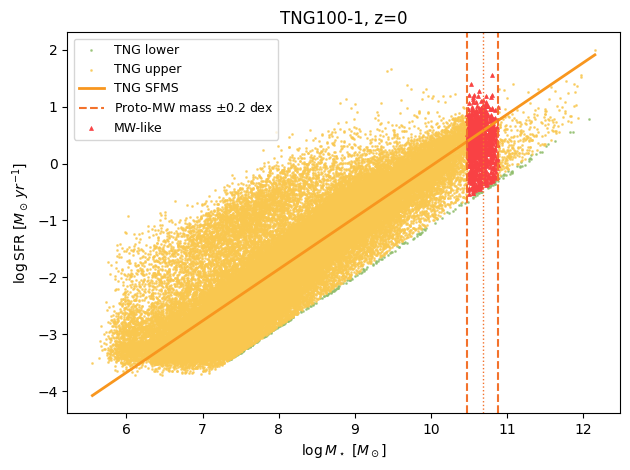

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16672\4121173162.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


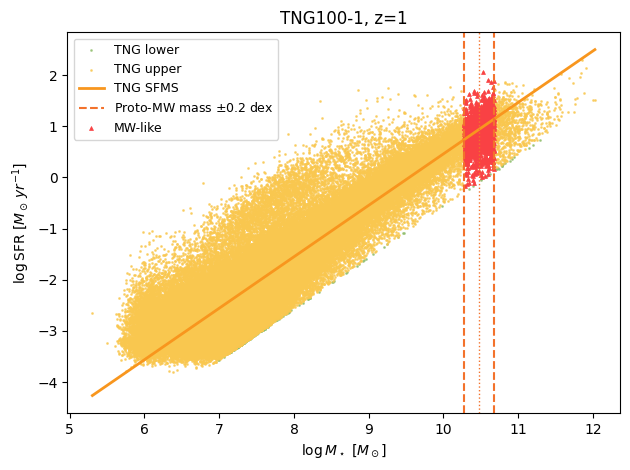

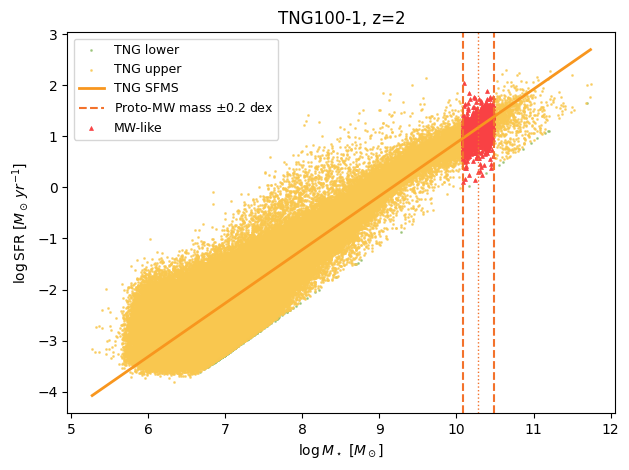

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16672\4121173162.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


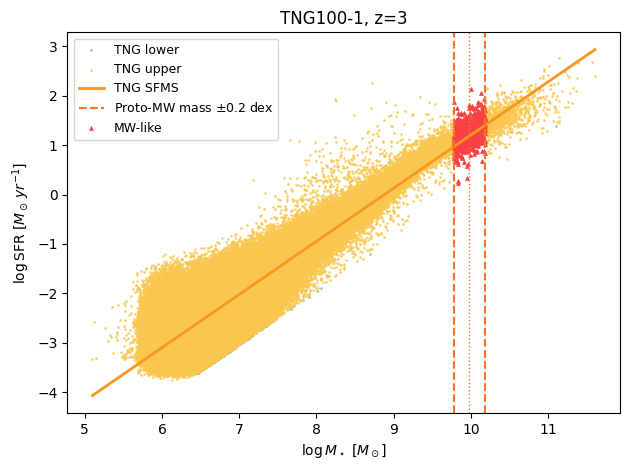

In [16]:
import matplotlib.pyplot as plt

for z in snapshot_redshifts.values():

    upper = TNG_upper_fit[z]["upper"]
    lower = TNG_upper_fit[z]["lower"]
    
    mw_mass_like = TNG_upper_fit[z]["mw_mass_like"]

    tng_huber = TNG_upper_fit[z]["huber"]
    df_sfms = TNG_upper_fit[z]["all"]


    
    
    

    plt.figure()

    # TNG lower
    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=1,
        alpha=0.7,
        color="#90be6d",
        label="TNG lower"
    )

    # TNG upper
    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=1,
        alpha=0.7,
        color="#f9c74f",
        label="TNG upper"
    )

    # TNG SFMS
    x_tng = np.linspace(
        df_sfms["logM"].min(),
        df_sfms["logM"].max(),
        200
    )

    y_tng = tng_huber.predict(
        x_tng.reshape(-1, 1)
    )

    plt.plot(
        x_tng,
        y_tng,
        color="#f8961e",
        linestyle="-",
        linewidth=2,
        label="TNG SFMS"
    )

    # MW maseni opseg
    plt.axvline(
        protoMWmass[z] - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        protoMWmass[z] + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm0.2$ dex"
    )

    # Proto-MW masa
    plt.axvline(
        protoMWmass[z],
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )

    # MW-like galaksije
    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=8,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )

    plt.xlabel(r"$\log M_\star\ [M_\odot]$")
    plt.ylabel(r"$\log \mathrm{SFR}\ [M_\odot\,yr^{-1}]$")
    plt.title(f"TNG100-1, z={z}")

    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

In [17]:
for z in snapshot_redshifts.values():

    mw_mass_like = TNG_upper_fit[z]["mw_mass_like"]

    median_logSFR = mw_mass_like["logSFR"].median()

    p16 = np.percentile(mw_mass_like["logSFR"], 16)
    p84 = np.percentile(mw_mass_like["logSFR"], 84)

    print(
        f"z = {z}: "
        f"median logSFR = {median_logSFR:.4f}, "
        f"16–84% interval = [{p16:.4f}, {p84:.4f}]"
    ) 

z = 0: median logSFR = 0.3740, 16–84% interval = [-0.0532, 0.7380]
z = 1: median logSFR = 0.9298, 16–84% interval = [0.6290, 1.1730]
z = 2: median logSFR = 1.1133, 16–84% interval = [0.8853, 1.3374]
z = 3: median logSFR = 1.2287, 16–84% interval = [1.0597, 1.4121]


# TNG I COSMOS GRAFICI

ucitavanje cosmos podataka
Broj COSMOS objekata nakon filtriranja: 493803
COSMOS SFMS fit z=0: slope = 0.5981, intercept = -5.9867
COSMOS SFMS fit z=1: slope = 0.6114, intercept = -5.4902
COSMOS SFMS fit z=2: slope = 0.6586, intercept = -5.4334
COSMOS SFMS fit z=3: slope = 0.6003, intercept = -4.7102

COSMOS | z ≈ 0
Ukupan broj COSMOS galaksija: 78740
Upper populacija: 69049
Lower populacija: 9691
--------------------------------------------------
MW-like populacija: N = 610
Median logSFR = 0.2800
16–84% interval = [-0.3000, 0.7800]
--------------------------------------------------
SFMS nagib: 0.5981
SFMS odsečak: -5.9867


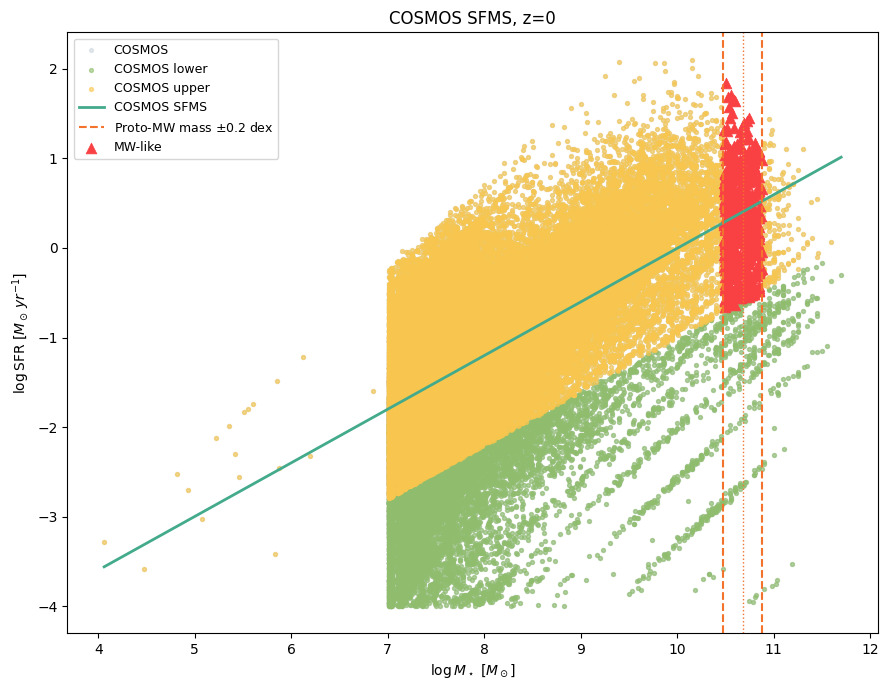


COSMOS | z ≈ 1
Ukupan broj COSMOS galaksija: 125257
Upper populacija: 111214
Lower populacija: 14043
--------------------------------------------------
MW-like populacija: N = 3373
Median logSFR = 1.2100
16–84% interval = [0.3300, 1.6300]
--------------------------------------------------
SFMS nagib: 0.6114
SFMS odsečak: -5.4902


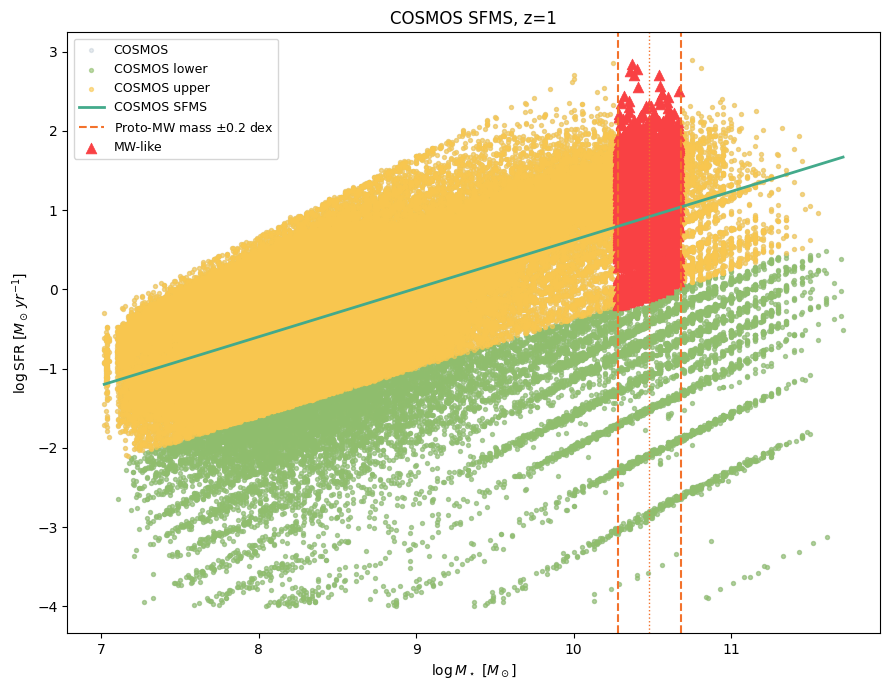


COSMOS | z ≈ 2
Ukupan broj COSMOS galaksija: 166470
Upper populacija: 153818
Lower populacija: 12652
--------------------------------------------------
MW-like populacija: N = 10103
Median logSFR = 1.5100
16–84% interval = [1.1100, 1.9400]
--------------------------------------------------
SFMS nagib: 0.6586
SFMS odsečak: -5.4334


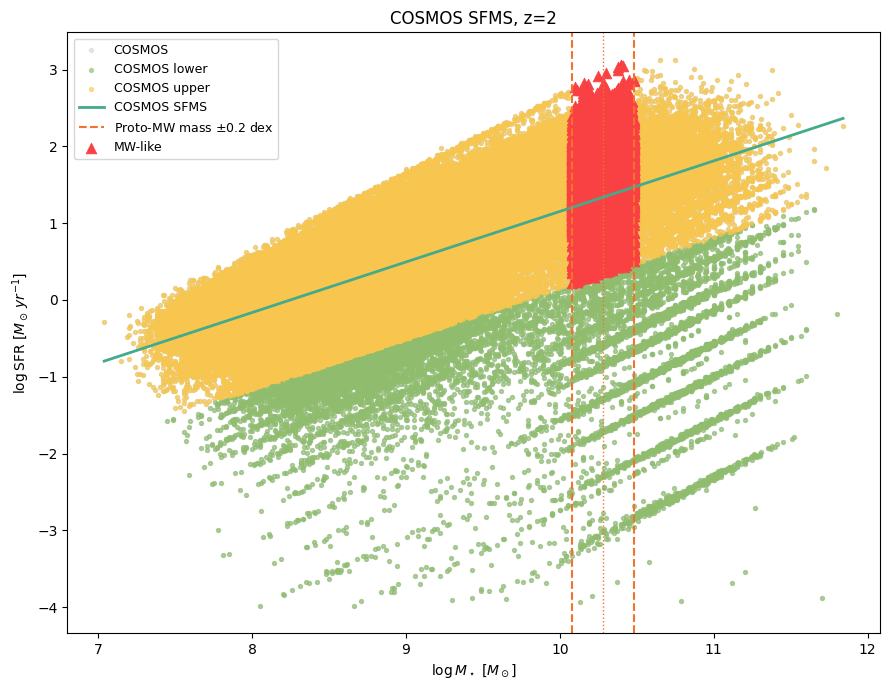


COSMOS | z ≈ 3
Ukupan broj COSMOS galaksija: 123336
Upper populacija: 118493
Lower populacija: 4843
--------------------------------------------------
MW-like populacija: N = 15482
Median logSFR = 1.3700
16–84% interval = [0.8800, 1.8300]
--------------------------------------------------
SFMS nagib: 0.6003
SFMS odsečak: -4.7102


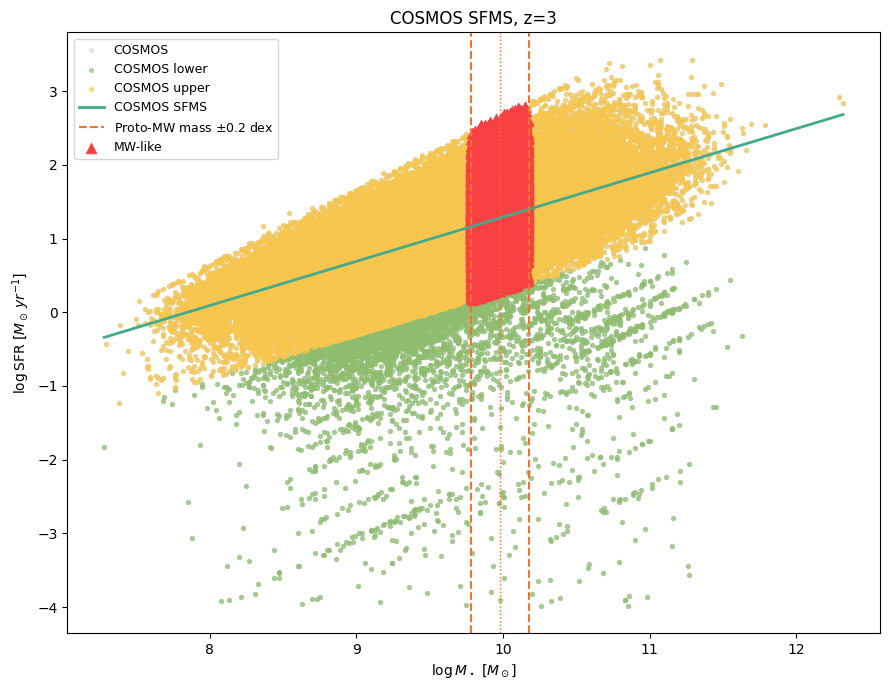

In [19]:
import requests
import pandas as pd
import numpy as np
from sklearn.linear_model import HuberRegressor
import matplotlib.pyplot as plt
from astropy.table import Table
import os
import time

COSMOS_FILE = "asu.fit"

protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

print("ucitavanje cosmos podataka")

cos = Table.read(
    COSMOS_FILE,
    format="fits"
).to_pandas()


#cosmos filteri

cos = cos[
    (cos["zphot"] > 0) &
    (cos["zphot"] < 4) &
    (cos["MassMed"] > 0) &
    (cos["SFR"] > -5)
].copy()


#cosmos velicine

cos["logM"] = cos["MassMed"]
cos["logSFR"] = cos["SFR"]


#sfms filter

cos = cos[
    #cos["logSFR"] > -3.5
    cos["logSFR"] > -4
].copy()


print(
    f"Broj COSMOS objekata nakon filtriranja: {len(cos)}"
)

def get_cosmos_bin(z):

    if z == 0:

        return cos[
            (cos["zphot"] >= 0) &
            (cos["zphot"] < 0.5)
        ].copy()

    elif z == 1:

        return cos[
            (cos["zphot"] >= 0.5) &
            (cos["zphot"] < 1)
        ].copy()

    elif z == 2:

        return cos[
            (cos["zphot"] >= 1) &
            (cos["zphot"] < 2)
        ].copy()

    elif z == 3:

        return cos[
            (cos["zphot"] >= 2) &
            (cos["zphot"] < 4)
        ].copy()

cosmos_fits = {}


for z in range(4):

    cos_sub = get_cosmos_bin(z)

    if len(cos_sub) < 2:

        print(
            f"Premalo COSMOS objekata za z={z}"
        )

        continue


    X = (
        cos_sub["logM"]
        .values
        .reshape(-1, 1)
    )

    y = cos_sub["logSFR"].values


    huber = HuberRegressor()

    huber.fit(
        X,
        y
    )


    cosmos_fits[z] = huber


    print(
        f"COSMOS SFMS fit z={z}: "
        f"slope = {huber.coef_[0]:.4f}, "
        f"intercept = {huber.intercept_:.4f}"
    )

COSMOS_populations = {}
COSMOS_MW_statistics = {}


for z in cosmos_fits.keys():

    print()
    print("=" * 70)
    print(f"COSMOS | z ≈ {z}")
    print("=" * 70)


    cos_sub = get_cosmos_bin(z).copy()


    X = cos_sub["logM"].values.reshape(-1, 1)
    y = cos_sub["logSFR"].values

    cosmos_huber = HuberRegressor()
    cosmos_huber.fit(X, y)

    cos_sub["SFMS_fit"] = cosmos_huber.predict(X)


    cos_sub["delta_logSFR"] = (
        cos_sub["logSFR"] - cos_sub["SFMS_fit"]
    )


    upper = cos_sub[
        cos_sub["delta_logSFR"] > -1.0
    ].copy()

    lower = cos_sub[
        cos_sub["delta_logSFR"] <= -1.0
    ].copy()


    MW_mass = protoMWmass[z]

    mw_mass_like = upper[
        np.abs(
            upper["logM"] - MW_mass
        ) <= 0.2
    ].copy()


    N = len(mw_mass_like)



    mw_logSFR = mw_mass_like["logSFR"].values

    median_logSFR = np.median(mw_logSFR)

    p16 = np.percentile(mw_logSFR, 16)

    p84 = np.percentile(mw_logSFR, 84)


    

    COSMOS_populations[z] = {

        "all": cos_sub,

        "upper": upper,

        "lower": lower,

        "mw_mass_like": mw_mass_like,

        "huber": cosmos_huber
    }


    COSMOS_MW_statistics[z] = {

        "N": N,

        "median_logSFR": median_logSFR,

        "p16_logSFR": p16,

        "p84_logSFR": p84
    }
    
    
    
    print(f"Ukupan broj COSMOS galaksija: {len(cos_sub)}")

    print(f"Upper populacija: {len(upper)}")

    print(f"Lower populacija: {len(lower)}")

    print("-" * 50)

    print(f"MW-like populacija: N = {N}")

    print(f"Median logSFR = {median_logSFR:.4f}")

    print(f"16–84% interval = [{p16:.4f}, {p84:.4f}]")

    print("-" * 50)

    print(f"SFMS nagib: {cosmos_huber.coef_[0]:.4f}")

    print(f"SFMS odsečak: {cosmos_huber.intercept_:.4f}")


    plt.figure(figsize=(9, 7))


    plt.scatter(
        cos_sub["logM"],
        cos_sub["logSFR"],
        s=8,
        alpha=0.15,
        color="#577590",
        label="COSMOS"
    )


    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=8,
        alpha=0.6,
        color="#90be6d",
        label="COSMOS lower"
    )


    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=8,
        alpha=0.6,
        color="#f9c74f",
        label="COSMOS upper"
    )


    x_cos = np.linspace(
        cos_sub["logM"].min(),
        cos_sub["logM"].max(),
        200
    )

    y_cos = cosmos_huber.predict(
        x_cos.reshape(-1, 1)
    )

    plt.plot(
        x_cos,
        y_cos,
        color="#43aa8b",
        linewidth=2,
        label="COSMOS SFMS"
    )


    plt.axvline(
        MW_mass - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        MW_mass + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm 0.2$ dex"
    )


    plt.axvline(
        MW_mass,
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )


    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=60,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )


    plt.xlabel(r"$\log M_\star\ [M_\odot]$")

    plt.ylabel(r"$\log \mathrm{SFR}\ "r"[M_\odot\,yr^{-1}]$")

    plt.title(f"COSMOS SFMS, z={z}")

    plt.legend(fontsize=9)

    plt.tight_layout()

    plt.show()

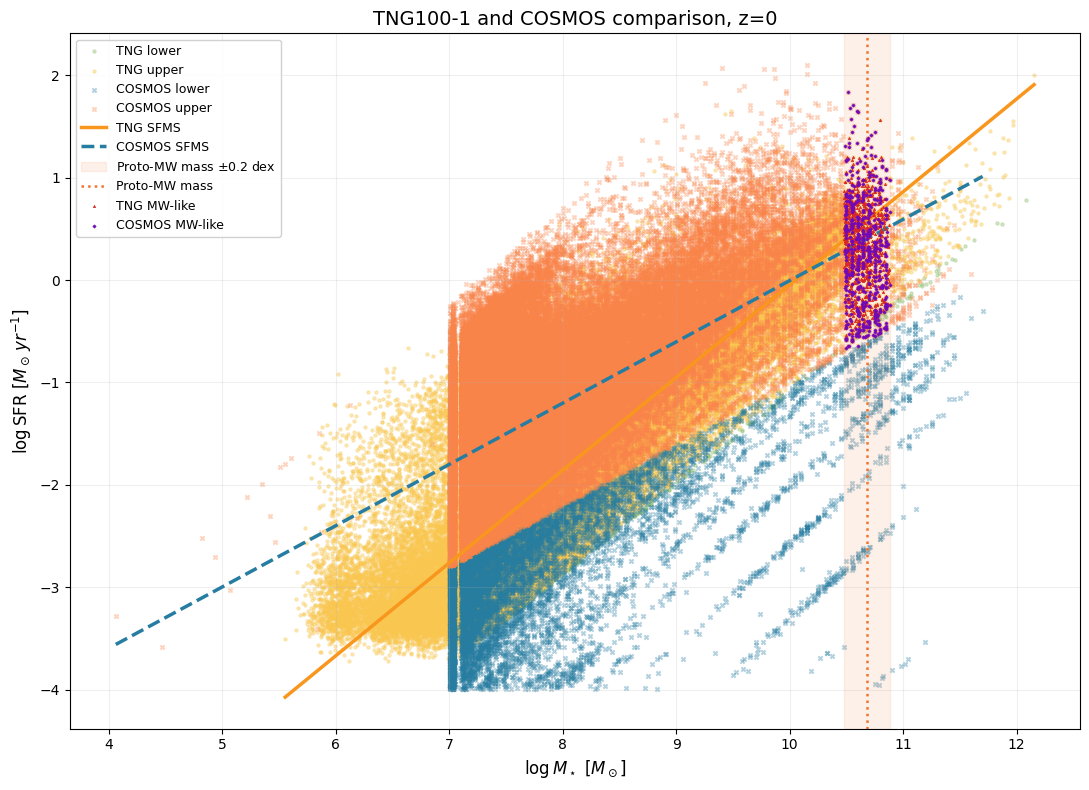

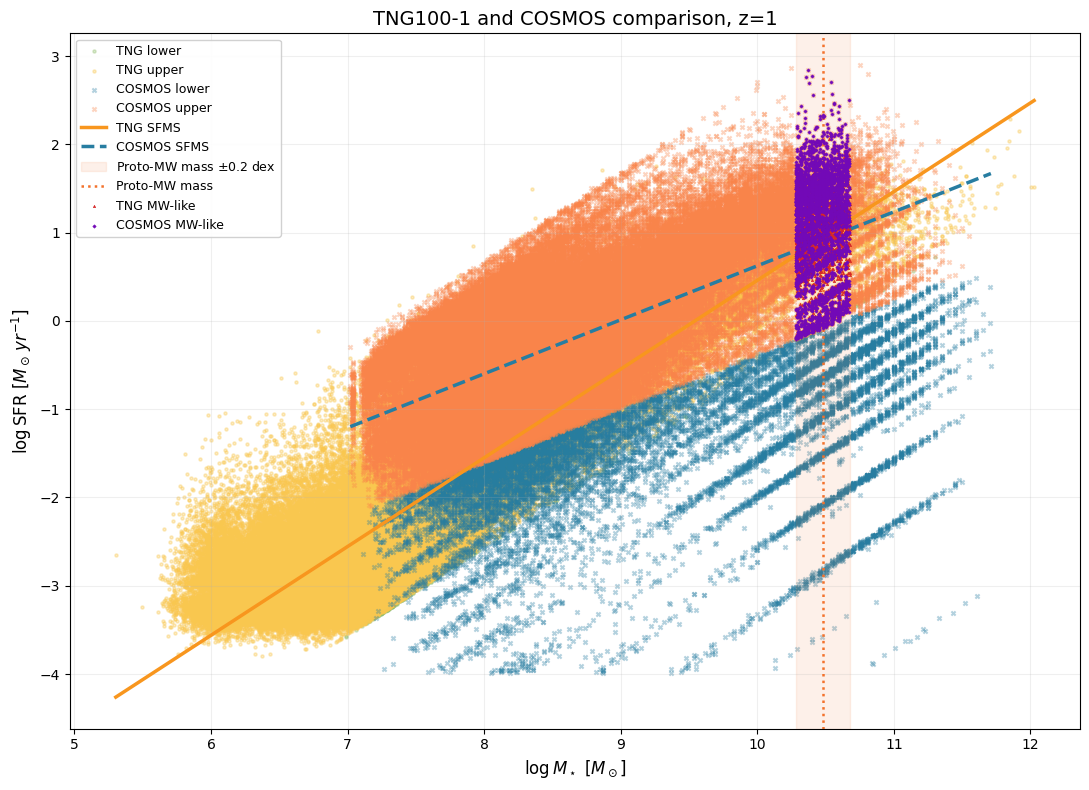

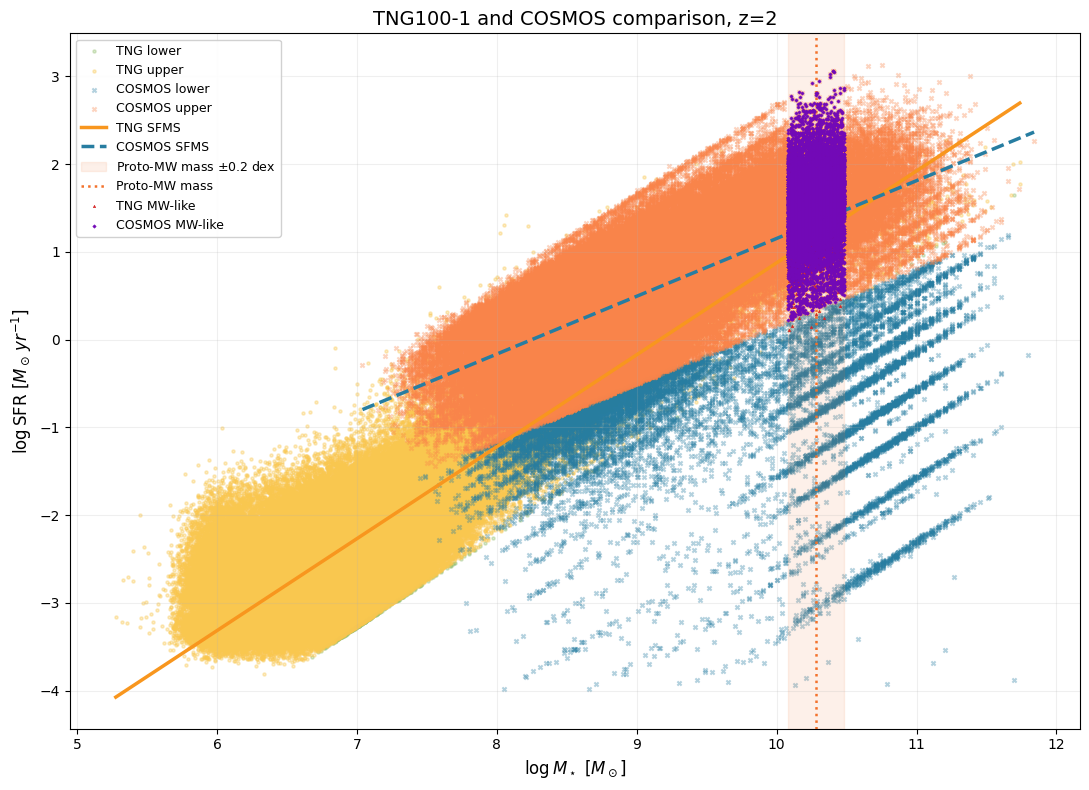

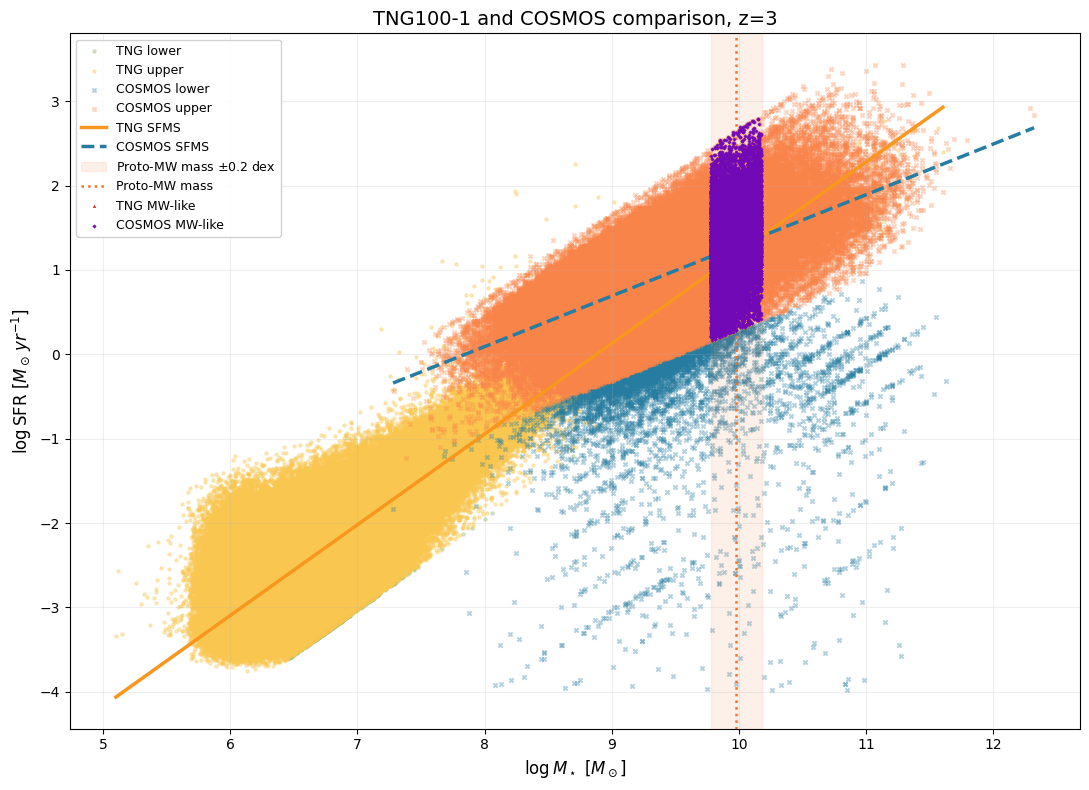

In [20]:
import numpy as np
import matplotlib.pyplot as plt

for z in snapshot_redshifts.values():

    # Provera da li postoje podaci za oba uzorka
    if z not in TNG_populations or z not in COSMOS_populations:
        print(f"Nedostaju podaci za z={z}")
        continue

    tng_upper = TNG_upper_fit[z]["upper"]
    tng_lower = TNG_upper_fit[z]["lower"]
    tng_mw = TNG_upper_fit[z]["mw_mass_like"]
    tng_huber = TNG_upper_fit[z]["huber"]
    tng_all = TNG_upper_fit[z]["all"]


    cos_upper = COSMOS_populations[z]["upper"]
    cos_lower = COSMOS_populations[z]["lower"]
    cos_mw = COSMOS_populations[z]["mw_mass_like"]
    cos_huber = COSMOS_populations[z]["huber"]
    cos_all = COSMOS_populations[z]["all"]

    MW_mass = protoMWmass[z]


    plt.figure(figsize=(11, 8))


    plt.scatter(
        tng_lower["logM"],
        tng_lower["logSFR"],
        s=5,
        alpha=0.35,
        color="#90be6d",
        marker="o",
        label="TNG lower"
    )

    plt.scatter(
        tng_upper["logM"],
        tng_upper["logSFR"],
        s=5,
        alpha=0.35,
        color="#f9c74f",
        marker="o",
        label="TNG upper"
    )


    plt.scatter(
        cos_lower["logM"],
        cos_lower["logSFR"],
        s=9,
        alpha=0.35,
        color="#277da1",
        marker="x",
        label="COSMOS lower"
    )

    plt.scatter(
        cos_upper["logM"],
        cos_upper["logSFR"],
        s=9,
        alpha=0.35,
        color="#f9844a",
        marker="x",
        label="COSMOS upper"
    )


    x_tng = np.linspace(
        tng_all["logM"].min(),
        tng_all["logM"].max(),
        200
    )

    y_tng = tng_huber.predict(
        x_tng.reshape(-1, 1)
    )

    plt.plot(
        x_tng,
        y_tng,
        color="#f8961e",
        linewidth=2.5,
        linestyle="-",
        label="TNG SFMS"
    )


    x_cos = np.linspace(
        cos_all["logM"].min(),
        cos_all["logM"].max(),
        200
    )

    y_cos = cos_huber.predict(
        x_cos.reshape(-1, 1)
    )

    plt.plot(
        x_cos,
        y_cos,
        color="#277da1",
        linewidth=2.5,
        linestyle="--",
        label="COSMOS SFMS"
    )


    plt.axvspan(
        MW_mass - 0.2,
        MW_mass + 0.2,
        color="#f3722c",
        alpha=0.10,
        label=r"Proto-MW mass $\pm 0.2$ dex"
    )

    plt.axvline(
        MW_mass,
        color="#f3722c",
        linestyle=":",
        linewidth=1.8,
        label="Proto-MW mass"
    )


    plt.scatter(
        tng_mw["logM"],
        tng_mw["logSFR"],
        marker="^",
        s=3,
        color="#d62828",
        linewidths=0.4,
        label="TNG MW-like",
        zorder=5
    )


    plt.scatter(
        cos_mw["logM"],
        cos_mw["logSFR"],
        marker="D",
        s=3,
        color="#7209b7",
        linewidths=0.4,
        label="COSMOS MW-like",
        zorder=5
    )


    plt.xlabel(
        r"$\log M_\star\ [M_\odot]$",
        fontsize=12
    )

    plt.ylabel(
        r"$\log \mathrm{SFR}\ [M_\odot\,yr^{-1}]$",
        fontsize=12
    )

    plt.title(
        f"TNG100-1 and COSMOS comparison, z={z}",
        fontsize=14
    )

    plt.legend(
        fontsize=9,
        loc="best",
        framealpha=0.9
    )

    plt.grid(
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

# METALICNOST

# 3D SFR weighted 

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
        id       logM    logSFR  Z_weighted  delta_logSFR
4       20  10.631641 -0.335965    0.013096     -0.864536
6       32  10.644636 -0.345226    0.045841     -0.885570
9       41  10.680394  0.889977    0.032064      0.317236
122  17211  10.682458  0.410602    0.033971     -0.164009
125  17216  10.585560  0.223236    0.060971     -0.263585

z = 0 | alpha = 1.0
Ukupan broj MW-like objekata = 804
Broj objekata u gornjih 10% = 81

Max-Np objekat
logM       = 10.8774
logSFR     = -0.0188
Z          = 5.040554e-02
Np         = 2.992485e+20

Gornjih 10% po Np
min(Np)    = 5.148842e+19
max(Np)    = 2.992485e+20
median(Np) = 6.825049e+19

Statistika svih objekata
min(Np)    = 9.226e+17
max(Np)    = 2.992e+20
median(Np) = 1.575e+19


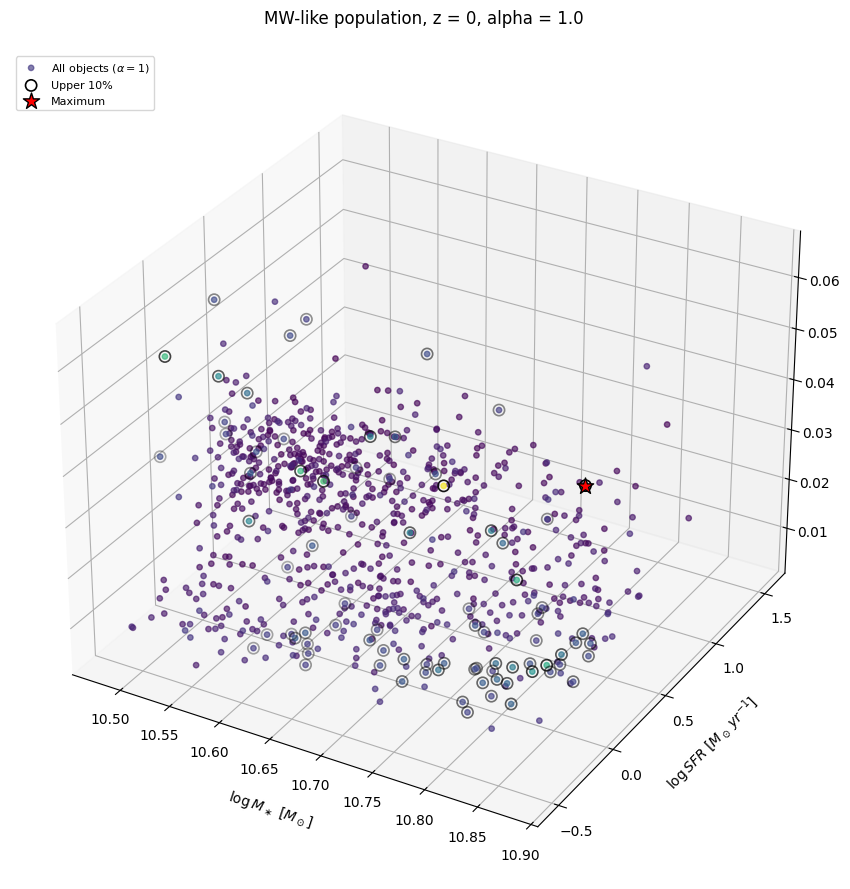


z = 0 | alpha = 0.0
Ukupan broj MW-like objekata = 804
Broj objekata u gornjih 10% = 81

Max-Np objekat
logM       = 10.8664
logSFR     = -0.2361
Z          = 1.982195e-02
Np         = 9.309604e+21

Gornjih 10% po Np
min(Np)    = 3.315766e+21
max(Np)    = 9.309604e+21
median(Np) = 4.653642e+21

Statistika svih objekata
min(Np)    = 4.512e+19
max(Np)    = 9.310e+21
median(Np) = 7.660e+20


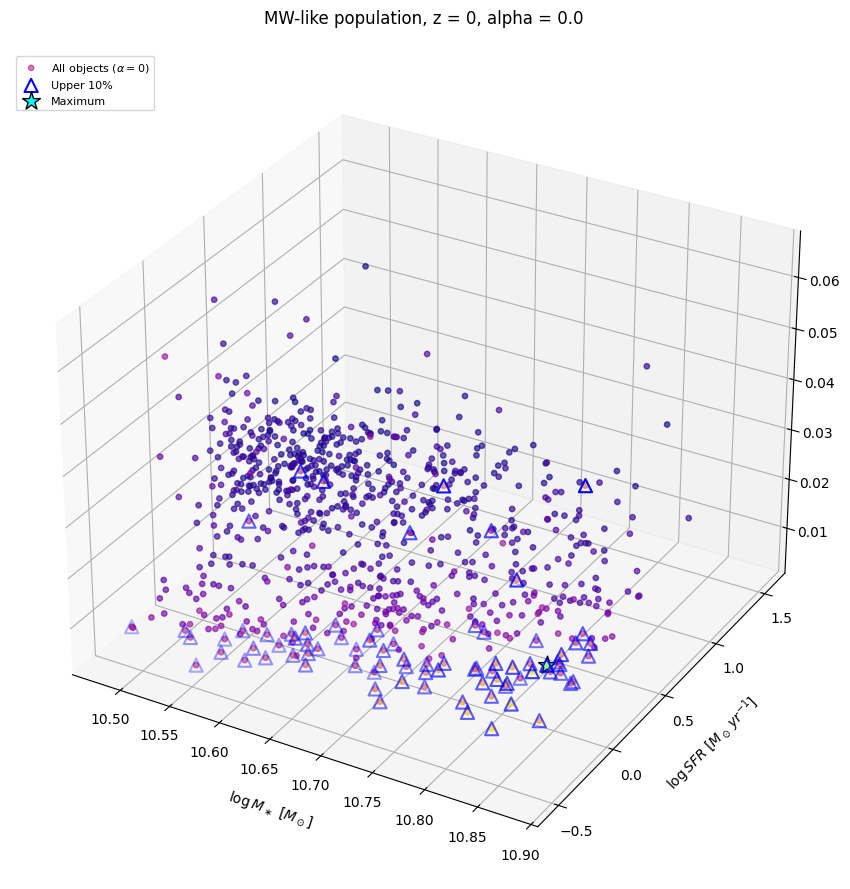

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
    id       logM    logSFR  Z_weighted  delta_logSFR
7    9  10.587407  1.044491    0.027741     -0.005774
8   10  10.664554  1.239006    0.027586      0.111193
10  13  10.669320  0.302072    0.013146     -0.830532
11  14  10.618810  1.407194    0.024700      0.325364
13  16  10.617486  1.159264    0.029178      0.078764

z = 1 | alpha = 1.0
Ukupan broj MW-like objekata = 1624
Broj objekata u gornjih 10% = 163

Max-Np objekat
logM       = 10.6317
logSFR     = 0.3299
Z          = 7.401130e-02
Np         = 6.350746e+19

Gornjih 10% po Np
min(Np)    = 6.795113e+18
max(Np)    = 6.350746e+19
median(Np) = 1.004017e+19

Statistika svih objekata
min(Np)    = 1.628e+17
max(Np)    = 6.351e+19
median(Np) = 2.251e+18


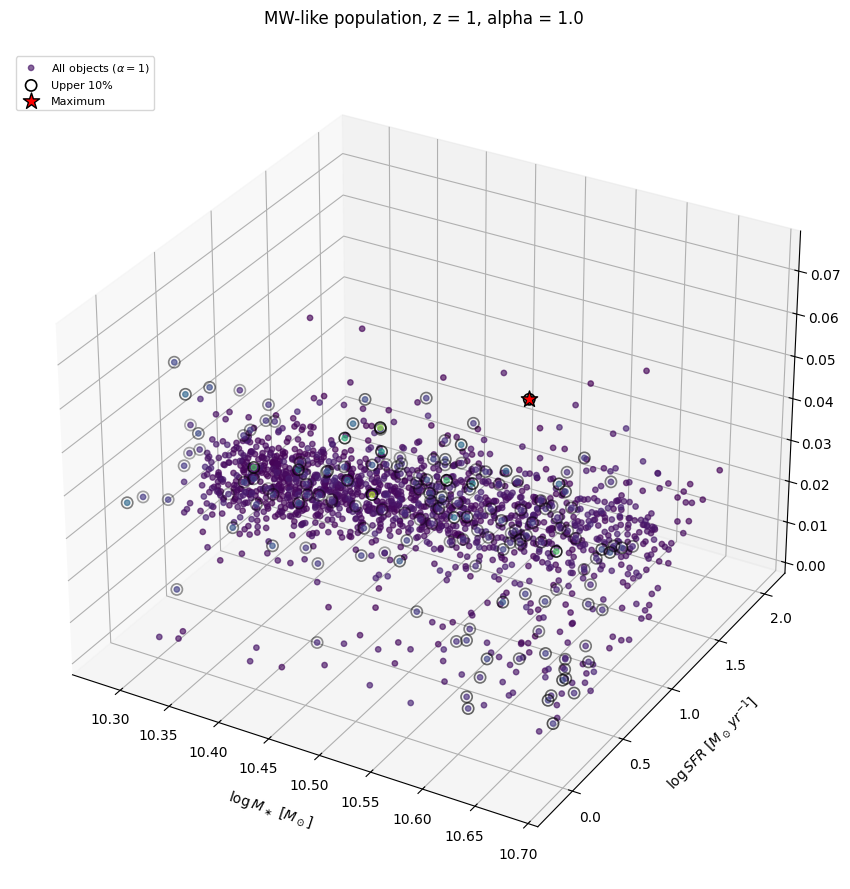


z = 1 | alpha = 0.0
Ukupan broj MW-like objekata = 1624
Broj objekata u gornjih 10% = 163

Max-Np objekat
logM       = 10.6748
logSFR     = 0.1567
Z          = 6.808630e-03
Np         = 1.559450e+21

Gornjih 10% po Np
min(Np)    = 2.647664e+20
max(Np)    = 1.559450e+21
median(Np) = 4.483185e+20

Statistika svih objekata
min(Np)    = 9.608e+18
max(Np)    = 1.559e+21
median(Np) = 9.729e+19


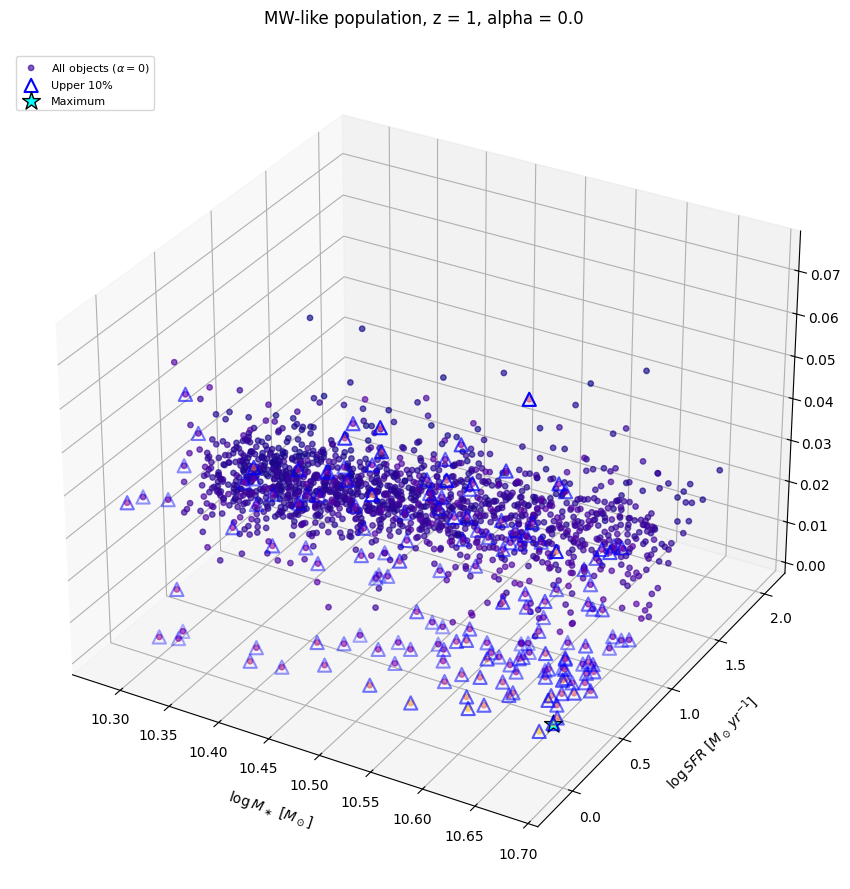

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
    id       logM    logSFR  Z_weighted  delta_logSFR
3    6  10.213575  0.933943    0.035141     -0.164942
4    7  10.205244  1.323088    0.023927      0.232931
5    8  10.182852  0.776456    0.032868     -0.290241
9   13  10.106582  0.875870    0.022361     -0.110921
11  16  10.242908  0.144849    0.041629     -0.984767

z = 2 | alpha = 1.0
Ukupan broj MW-like objekata = 1457
Broj objekata u gornjih 10% = 146

Max-Np objekat
logM       = 10.3367
logSFR     = 0.2503
Z          = 6.699750e-02
Np         = 1.774708e+19

Gornjih 10% po Np
min(Np)    = 1.509124e+18
max(Np)    = 1.774708e+19
median(Np) = 2.114323e+18

Statistika svih objekata
min(Np)    = 3.479e+16
max(Np)    = 1.775e+19
median(Np) = 5.818e+17


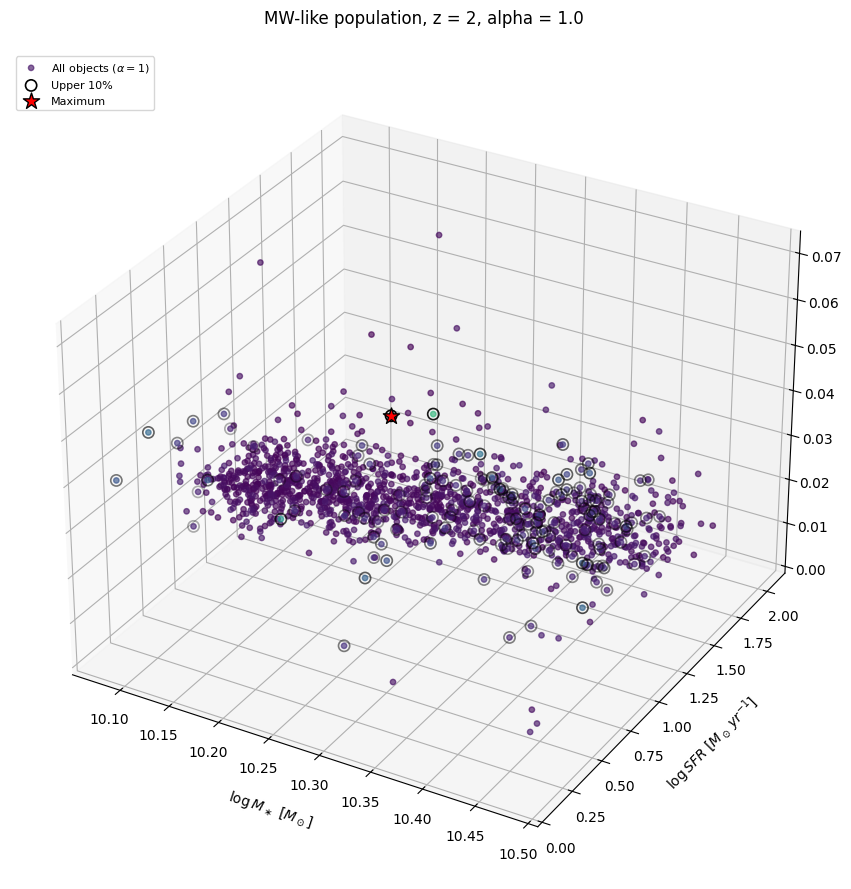


z = 2 | alpha = 0.0
Ukupan broj MW-like objekata = 1457
Broj objekata u gornjih 10% = 146

Max-Np objekat
logM       = 10.4531
logSFR     = 0.3882
Z          = 3.742082e-03
Np         = 3.296143e+20

Gornjih 10% po Np
min(Np)    = 5.354890e+19
max(Np)    = 3.296143e+20
median(Np) = 6.954320e+19

Statistika svih objekata
min(Np)    = 1.450e+18
max(Np)    = 3.296e+20
median(Np) = 2.560e+19


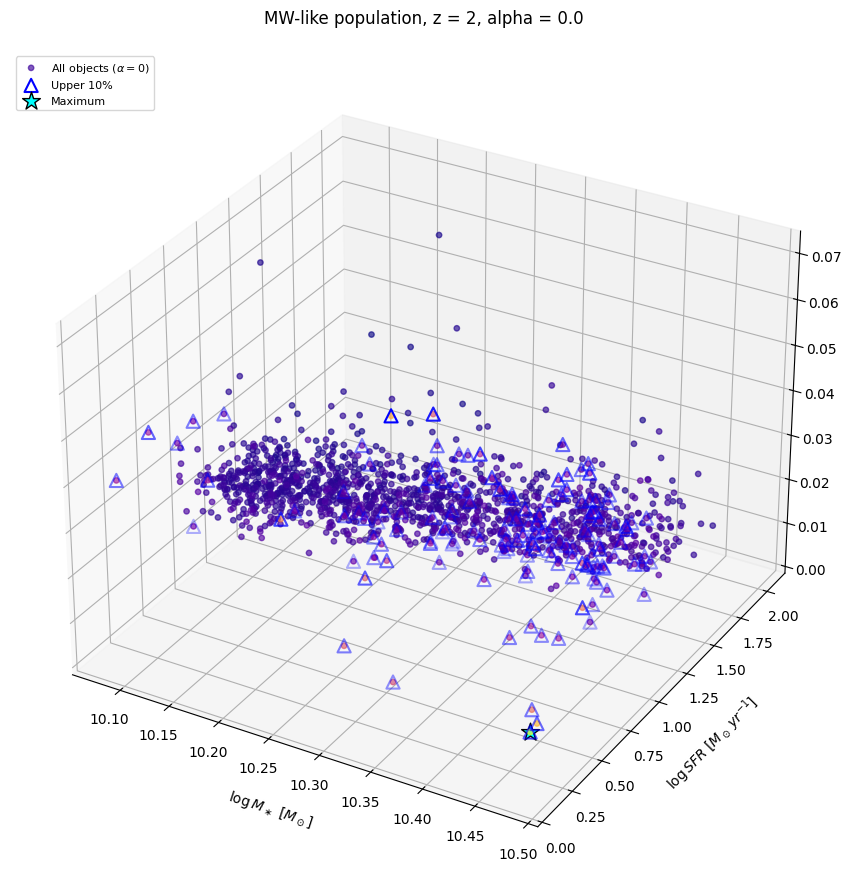

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
      id       logM    logSFR  Z_weighted  delta_logSFR
15    15  10.003863  1.341132    0.018279      0.131610
16    16  10.087068  1.816583    0.019663      0.517608
17    17   9.792892  0.991021    0.018348      0.008313
109  845  10.130707  1.386197    0.015857      0.040306
117  853  10.013126  1.794953    0.021491      0.575473

z = 3 | alpha = 1.0
Ukupan broj MW-like objekata = 1112
Broj objekata u gornjih 10% = 112

Max-Np objekat
logM       = 10.1452
logSFR     = 0.6782
Z          = 4.208019e-02
Np         = 1.722963e+18

Gornjih 10% po Np
min(Np)    = 2.053620e+17
max(Np)    = 1.722963e+18
median(Np) = 2.709861e+17

Statistika svih objekata
min(Np)    = 7.730e+15
max(Np)    = 1.723e+18
median(Np) = 7.487e+16


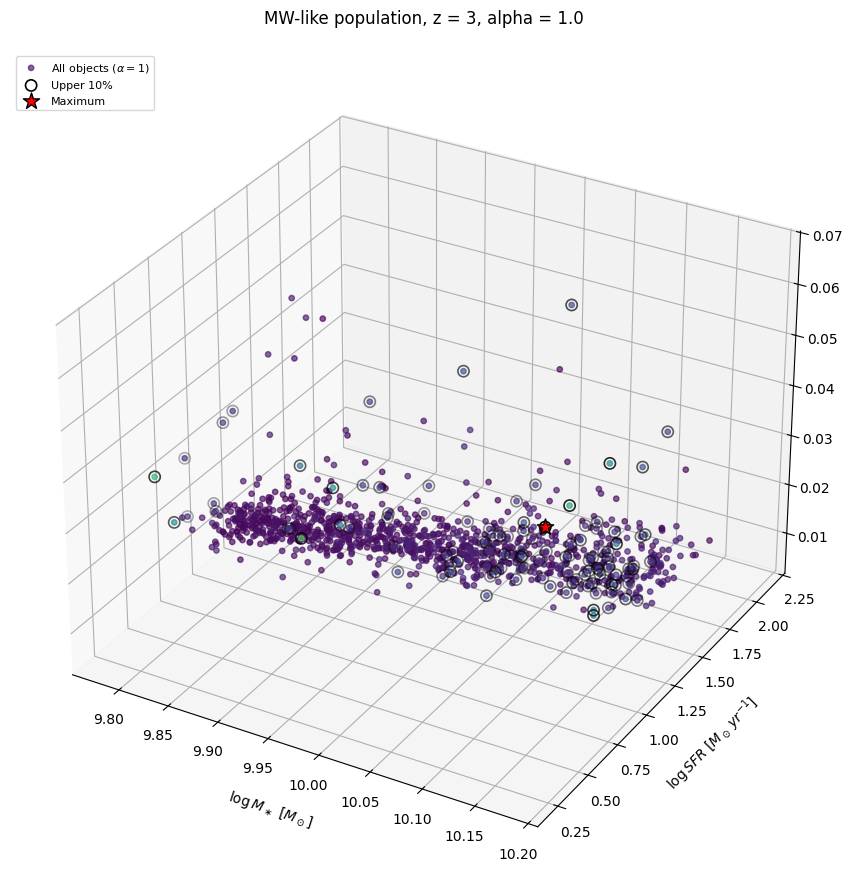


z = 3 | alpha = 0.0
Ukupan broj MW-like objekata = 1112
Broj objekata u gornjih 10% = 112

Max-Np objekat
logM       = 10.1452
logSFR     = 0.6782
Z          = 4.208019e-02
Np         = 4.094475e+19

Gornjih 10% po Np
min(Np)    = 9.612356e+18
max(Np)    = 4.094475e+19
median(Np) = 1.146399e+19

Statistika svih objekata
min(Np)    = 5.018e+17
max(Np)    = 4.094e+19
median(Np) = 4.854e+18


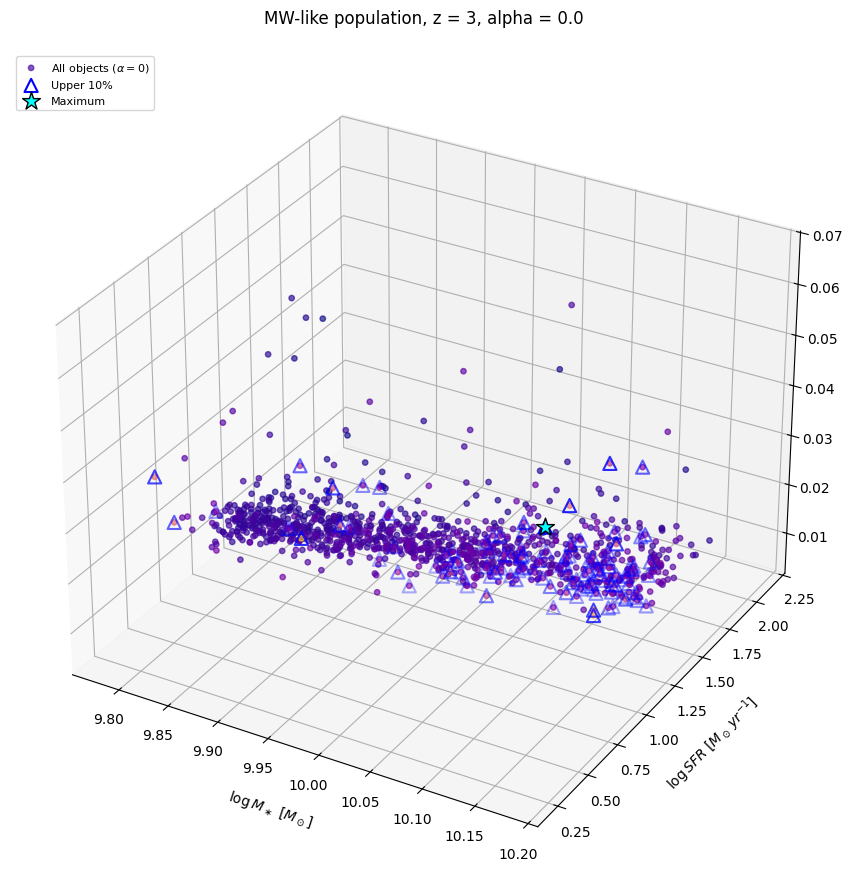

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Parametri alpha
param_alpha = [1.0, 0.0]

for z in range(4):

    # Uzimanje MW-like populacije nakon drugog SFMS fita
    df = MWupper[z].copy()

    print(df.columns.tolist())
    print(df.head())

    # Masa
    logM = df["logM"].values
    M = 10**logM

    # SFR
    logSFR = df["logSFR"].values
    SFR = 10**logSFR

    # Metalicnost
    Z = df["Z_weighted"].values

    N = len(df)

    for alpha in param_alpha:
        Np = M**2 * Z**alpha / SFR

        # Maksimalni Np objekat
        max_index = np.argmax(Np)

        max_Np = Np[max_index]
        max_logM = logM[max_index]
        max_logSFR = logSFR[max_index]
        max_Z = Z[max_index]

        # Gornjih 10% objekata po Np
        n_top10 = max(1, int(np.ceil(0.10 * N)))

        top10_indices = np.argsort(Np)[-n_top10:]

        top10_logM = logM[top10_indices]
        top10_logSFR = logSFR[top10_indices]
        top10_Z = Z[top10_indices]
        top10_Np = Np[top10_indices]

        # Statistika
        print()
        print("=" * 65)
        print(f"z = {z} | alpha = {alpha}")
        print("=" * 65)

        print(f"Ukupan broj MW-like objekata = {N}")
        print(f"Broj objekata u gornjih 10% = {n_top10}")

        print("\nMax-Np objekat")
        print(f"logM       = {max_logM:.4f}")
        print(f"logSFR     = {max_logSFR:.4f}")
        print(f"Z          = {max_Z:.6e}")
        print(f"Np         = {max_Np:.6e}")

        print("\nGornjih 10% po Np")
        print(f"min(Np)    = {top10_Np.min():.6e}")
        print(f"max(Np)    = {top10_Np.max():.6e}")
        print(f"median(Np) = {np.median(top10_Np):.6e}")

        print("\nStatistika svih objekata")
        print(f"min(Np)    = {Np.min():.3e}")
        print(f"max(Np)    = {Np.max():.3e}")
        print(f"median(Np) = {np.median(Np):.3e}")

        fig = plt.figure(figsize=(12, 9))
        ax = fig.add_subplot(111, projection="3d")

        # Grafik za alpha = 1
        if alpha == 1.0:

            ax.scatter(
                logM,
                logSFR,
                Z,
                c=Np,
                cmap="viridis",
                s=15,
                alpha=0.65,
                label=r"All objects ($\alpha=1$)"
            )

            ax.scatter(
                top10_logM,
                top10_logSFR,
                top10_Z,
                s=65,
                facecolors="none",
                edgecolors="black",
                linewidths=1.2,
                label=r"Upper 10%"
            )

            ax.scatter(
                [max_logM],
                [max_logSFR],
                [max_Z],
                s=150,
                marker="*",
                c="red",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        # Grafik za alpha = 0
        else:

            ax.scatter(
                logM,
                logSFR,
                Z,
                c=Np,
                cmap="plasma",
                s=15,
                alpha=0.65,
                label=r"All objects ($\alpha=0$)"
            )

            ax.scatter(
                top10_logM,
                top10_logSFR,
                top10_Z,
                s=90,
                facecolors="none",
                edgecolors="blue",
                linewidths=1.5,
                marker="^",
                label=r"Upper 10%"
            )

            ax.scatter(
                [max_logM],
                [max_logSFR],
                [max_Z],
                s=180,
                marker="*",
                c="cyan",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        ax.set_title(
            f"MW-like population, z = {z}, alpha = {alpha}",
            pad=20
        )

        ax.set_xlabel(r"$\log M_\ast\ [M_\odot]$", labelpad=10)
        ax.set_ylabel(r"$\log SFR\ [M_\odot\,yr^{-1}]$", labelpad=10)
        ax.set_zlabel("Z", labelpad=10)
        ax.legend(loc="upper left", fontsize=8)

        plt.tight_layout()
        plt.show()

# FMR


z = 0 | alpha = 1.0
Ukupan broj MW-like objekata = 804
Broj objekata u gornjih 10% = 81

MAX-Np OBJEKAT
logM       = 10.8664
logSFR     = -0.2361
Z (FMR)    = 9.083442e+00
Np         = 8.456323e+22

GORNJIH 10% PO Np
min(Np)    = 3.007959e+22
max(Np)    = 8.456323e+22
median(Np) = 4.223747e+22

STATISTIKA SVIH OBJEKATA
min(Np)    = 3.983e+20
max(Np)    = 8.456e+22
median(Np) = 6.912e+21


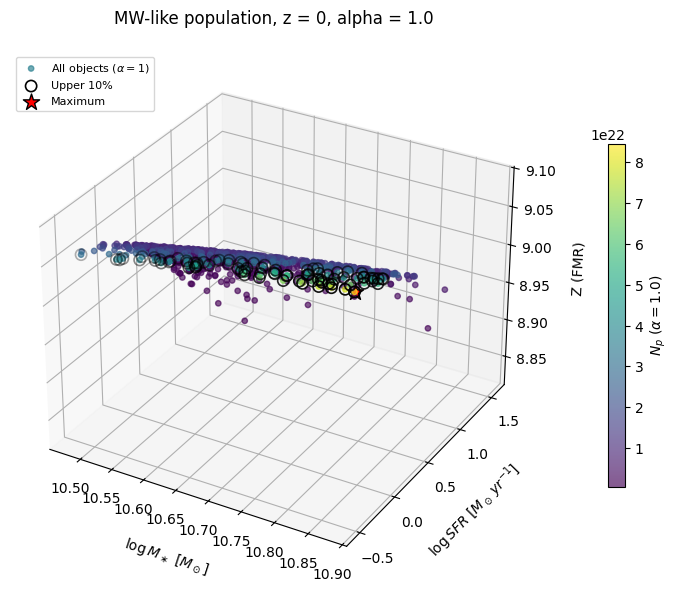


z = 0 | alpha = 0.0
Ukupan broj MW-like objekata = 804
Broj objekata u gornjih 10% = 81

MAX-Np OBJEKAT
logM       = 10.8664
logSFR     = -0.2361
Z (FMR)    = 9.083442e+00
Np         = 9.309604e+21

GORNJIH 10% PO Np
min(Np)    = 3.315766e+21
max(Np)    = 9.309604e+21
median(Np) = 4.653642e+21

STATISTIKA SVIH OBJEKATA
min(Np)    = 4.512e+19
max(Np)    = 9.310e+21
median(Np) = 7.660e+20


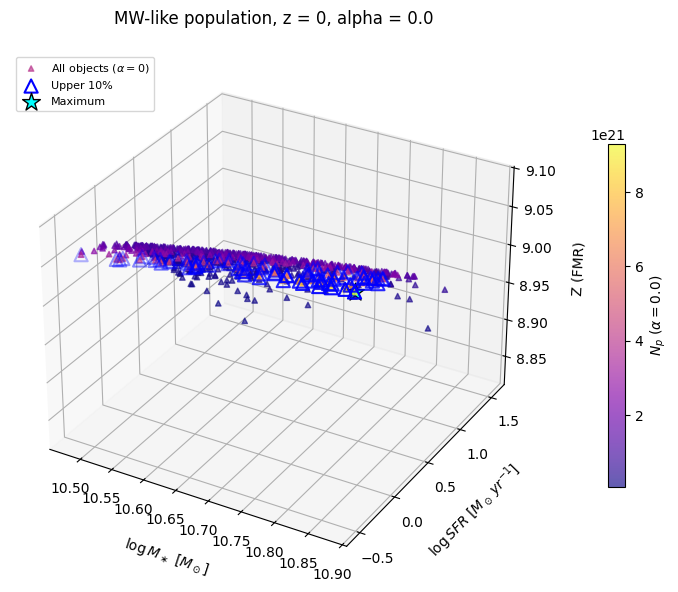


z = 1 | alpha = 1.0
Ukupan broj MW-like objekata = 1624
Broj objekata u gornjih 10% = 163

MAX-Np OBJEKAT
logM       = 10.6748
logSFR     = 0.1567
Z (FMR)    = 9.052589e+00
Np         = 1.411706e+22

GORNJIH 10% PO Np
min(Np)    = 2.375925e+21
max(Np)    = 1.411706e+22
median(Np) = 4.036363e+21

STATISTIKA SVIH OBJEKATA
min(Np)    = 8.313e+19
max(Np)    = 1.412e+22
median(Np) = 8.666e+20


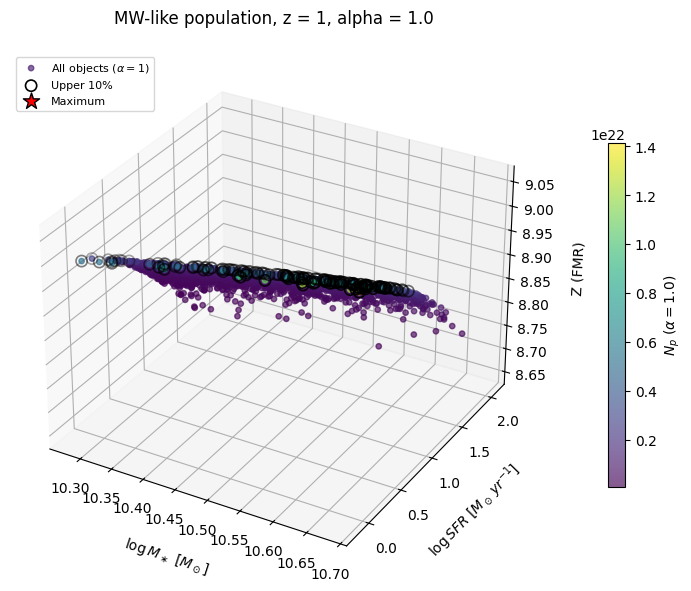


z = 1 | alpha = 0.0
Ukupan broj MW-like objekata = 1624
Broj objekata u gornjih 10% = 163

MAX-Np OBJEKAT
logM       = 10.6748
logSFR     = 0.1567
Z (FMR)    = 9.052589e+00
Np         = 1.559450e+21

GORNJIH 10% PO Np
min(Np)    = 2.647664e+20
max(Np)    = 1.559450e+21
median(Np) = 4.483185e+20

STATISTIKA SVIH OBJEKATA
min(Np)    = 9.608e+18
max(Np)    = 1.559e+21
median(Np) = 9.729e+19


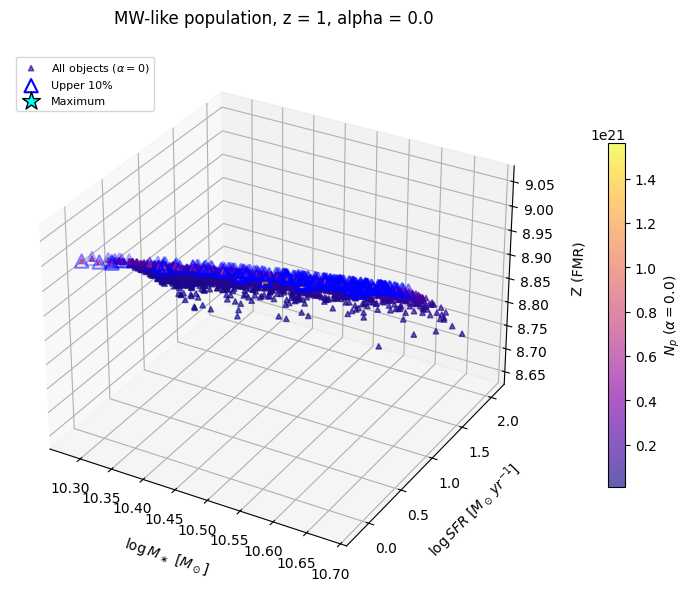


z = 2 | alpha = 1.0
Ukupan broj MW-like objekata = 1457
Broj objekata u gornjih 10% = 146

MAX-Np OBJEKAT
logM       = 10.4531
logSFR     = 0.3882
Z (FMR)    = 8.987262e+00
Np         = 2.962330e+21

GORNJIH 10% PO Np
min(Np)    = 4.745761e+20
max(Np)    = 2.962330e+21
median(Np) = 6.175974e+20

STATISTIKA SVIH OBJEKATA
min(Np)    = 1.226e+19
max(Np)    = 2.962e+21
median(Np) = 2.253e+20


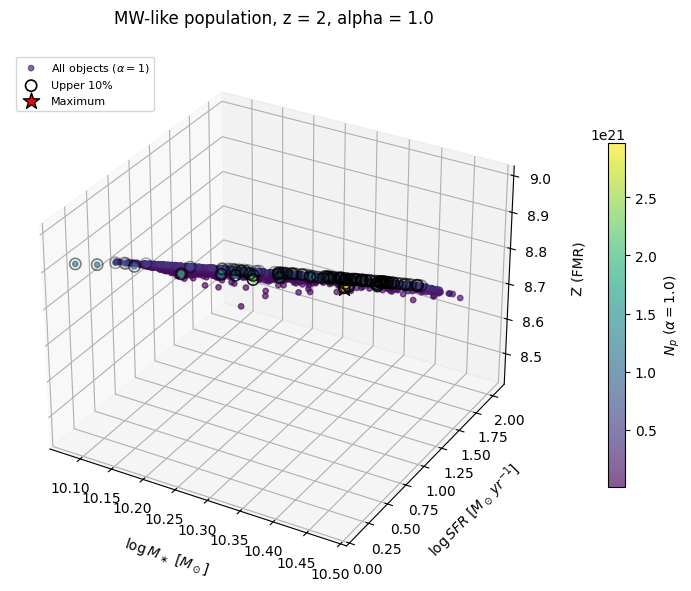


z = 2 | alpha = 0.0
Ukupan broj MW-like objekata = 1457
Broj objekata u gornjih 10% = 146

MAX-Np OBJEKAT
logM       = 10.4531
logSFR     = 0.3882
Z (FMR)    = 8.987262e+00
Np         = 3.296143e+20

GORNJIH 10% PO Np
min(Np)    = 5.354890e+19
max(Np)    = 3.296143e+20
median(Np) = 6.954320e+19

STATISTIKA SVIH OBJEKATA
min(Np)    = 1.450e+18
max(Np)    = 3.296e+20
median(Np) = 2.560e+19


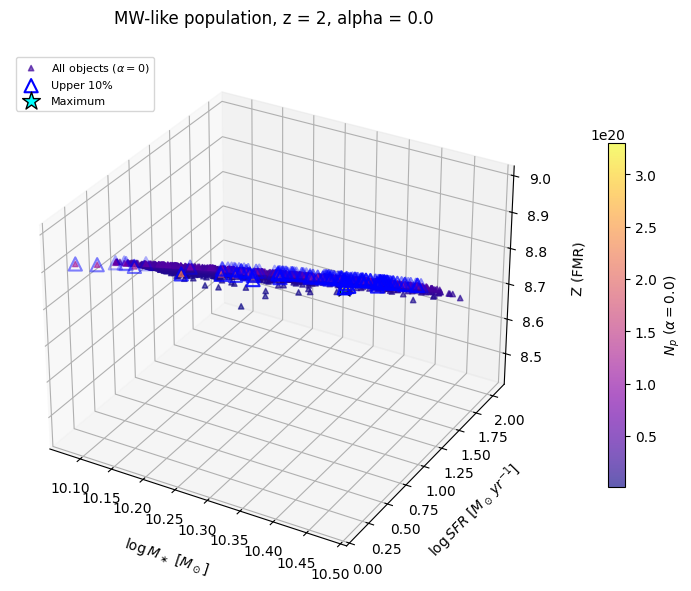


z = 3 | alpha = 1.0
Ukupan broj MW-like objekata = 1112
Broj objekata u gornjih 10% = 112

MAX-Np OBJEKAT
logM       = 10.1452
logSFR     = 0.6782
Z (FMR)    = 8.841748e+00
Np         = 3.620232e+20

GORNJIH 10% PO Np
min(Np)    = 8.361944e+19
max(Np)    = 3.620232e+20
median(Np) = 9.992180e+19

STATISTIKA SVIH OBJEKATA
min(Np)    = 4.172e+18
max(Np)    = 3.620e+20
median(Np) = 4.186e+19


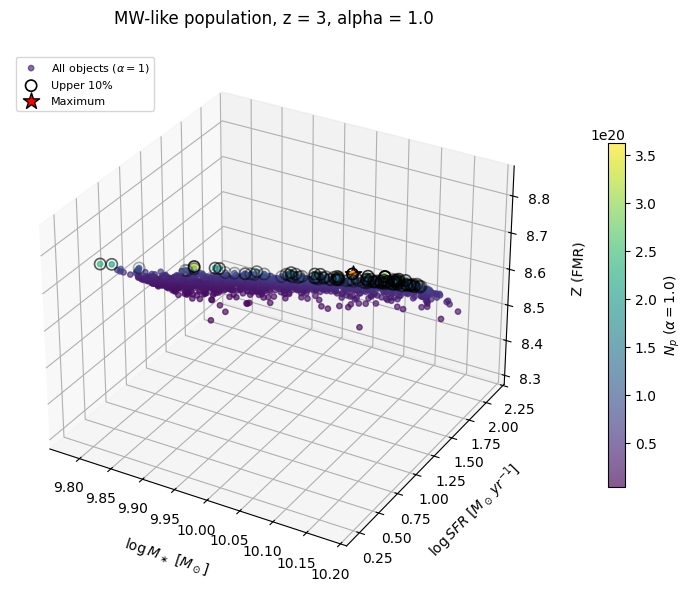


z = 3 | alpha = 0.0
Ukupan broj MW-like objekata = 1112
Broj objekata u gornjih 10% = 112

MAX-Np OBJEKAT
logM       = 10.1452
logSFR     = 0.6782
Z (FMR)    = 8.841748e+00
Np         = 4.094475e+19

GORNJIH 10% PO Np
min(Np)    = 9.612356e+18
max(Np)    = 4.094475e+19
median(Np) = 1.146399e+19

STATISTIKA SVIH OBJEKATA
min(Np)    = 5.018e+17
max(Np)    = 4.094e+19
median(Np) = 4.854e+18


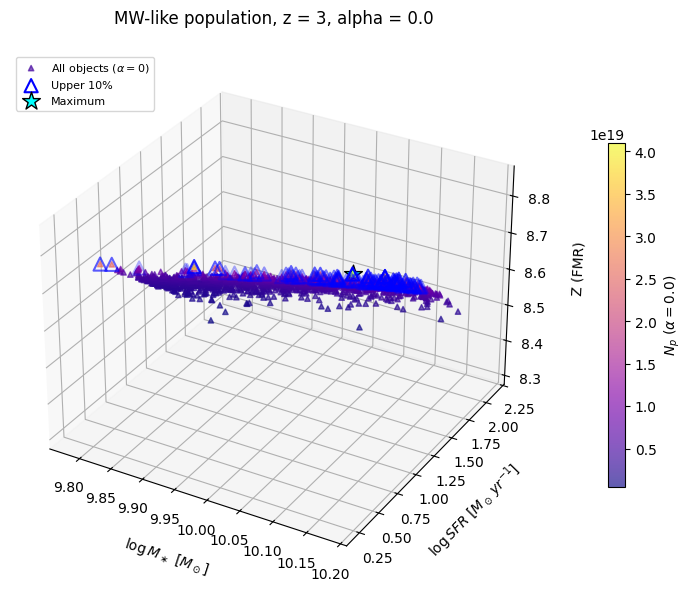

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Parametar alpha
param_alpha = [1.0, 0.0]

# FMR relacija
def FMR(m, s):
    return (
        8.9
        + 0.37*m
        - 0.14*s
        - 0.19*m**2
        + 0.12*m*s
        - 0.054*s**2
    )


for z in range(4):

    # MW-like populacija nakon drugog SFMS fita
    df = MWupper[z].copy()

    # Masa
    logM = df["logM"].values
    M = 10**logM

    # SFR
    logSFR = df["logSFR"].values
    SFR = 10**logSFR

    # FMR metalicnost
    m = logM - 10
    s = logSFR

    Z = FMR(m, s)

    N = len(df)

    for alpha in param_alpha:

        # Racunanje Np
        Np = (
            M**2
            * Z**alpha
            / SFR
        )

        df["Np"] = Np

        # Maksimalni Np objekat
        max_index = np.argmax(Np)

        max_Np = Np[max_index]

        max_logM = logM[max_index]
        max_logSFR = logSFR[max_index]
        max_Z = Z[max_index]

        # Gornjih 10% objekata po Np
        n_top10 = max(
            1,
            int(np.ceil(0.10 * N))
        )

        top10_indices = np.argsort(Np)[-n_top10:]

        top10_logM = logM[top10_indices]
        top10_logSFR = logSFR[top10_indices]
        top10_Z = Z[top10_indices]
        top10_Np = Np[top10_indices]

        # Statistika
        print()
        print("=" * 65)
        print(f"z = {z} | alpha = {alpha}")
        print("=" * 65)

        print(f"Ukupan broj MW-like objekata = {N}")
        print(f"Broj objekata u gornjih 10% = {n_top10}")

        print()
        print("MAX-Np OBJEKAT")

        print(f"logM       = {max_logM:.4f}")
        print(f"logSFR     = {max_logSFR:.4f}")
        print(f"Z (FMR)    = {max_Z:.6e}")
        print(f"Np         = {max_Np:.6e}")

        print()
        print("GORNJIH 10% PO Np")

        print(f"min(Np)    = {top10_Np.min():.6e}")
        print(f"max(Np)    = {top10_Np.max():.6e}")
        print(f"median(Np) = {np.median(top10_Np):.6e}")

        print()
        print("STATISTIKA SVIH OBJEKATA")

        print(f"min(Np)    = {Np.min():.3e}")
        print(f"max(Np)    = {Np.max():.3e}")
        print(f"median(Np) = {np.median(Np):.3e}")

        fig = plt.figure(figsize=(9, 6))

        ax = fig.add_subplot(
            111,
            projection="3d"
        )

        if alpha == 1.0:

            scatter = ax.scatter(
                logM,
                logSFR,
                Z,
                c=Np,
                cmap="viridis",
                s=15,
                alpha=0.65,
                label=r"All objects ($\alpha=1$)"
            )

            # Gornjih 10%
            ax.scatter(
                top10_logM,
                top10_logSFR,
                top10_Z,
                s=65,
                facecolors="none",
                edgecolors="black",
                linewidths=1.2,
                label="Upper 10%"
            )

            # Maksimum
            ax.scatter(
                [max_logM],
                [max_logSFR],
                [max_Z],
                s=150,
                marker="*",
                c="red",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        else:

            scatter = ax.scatter(
                logM,
                logSFR,
                Z,
                c=Np,
                cmap="plasma",
                s=15,
                alpha=0.65,
                marker="^",
                label=r"All objects ($\alpha=0$)"
            )

            # Gornjih 10%
            ax.scatter(
                top10_logM,
                top10_logSFR,
                top10_Z,
                s=90,
                facecolors="none",
                edgecolors="blue",
                linewidths=1.5,
                marker="^",
                label="Upper 10%"
            )

            # Maksimum
            ax.scatter(
                [max_logM],
                [max_logSFR],
                [max_Z],
                s=180,
                marker="*",
                c="cyan",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        ax.set_title(
            f"MW-like population, z = {z}, alpha = {alpha}",
            pad=20
        )

        ax.set_xlabel(
            r"$\log M_\ast\ [M_\odot]$",
            labelpad=10
        )

        ax.set_ylabel(
            r"$\log SFR\ [M_\odot\,yr^{-1}]$",
            labelpad=10
        )

        ax.set_zlabel(
            "Z (FMR)",
            labelpad=10
        )

        cbar = fig.colorbar(
            scatter,
            ax=ax,
            shrink=0.65,
            pad=0.08
        )

        cbar.set_label(
            rf"$N_p$ ($\alpha={alpha}$)"
        )

        # Legenda
        ax.legend(
            loc="upper left",
            fontsize=8
        )

        plt.tight_layout()
        plt.show()